<a href="https://colab.research.google.com/github/Mich-088/MAT422/blob/main/HW_3_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 3.4

**Logistic Regression**



In [151]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

np.set_printoptions(precision=4, suppress=True)



---


**SIGMOID/LOGISTIC FUNCTION**



___________________________________________________________________________




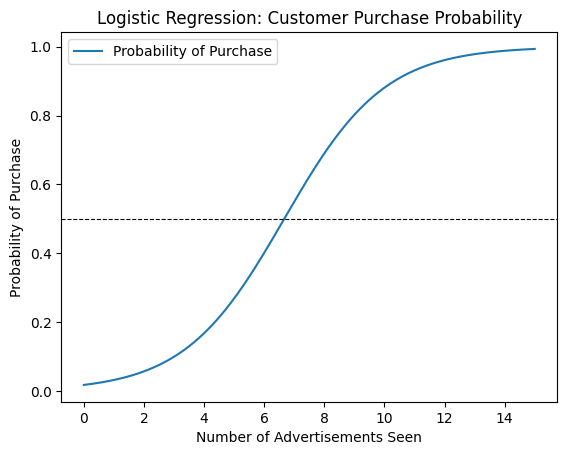



___________________________________________________________________________


In [152]:


print("___________________________________________________________________________")
print("\n")

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

ads = np.linspace(0, 15, 300)

z = -4 + 0.6 * ads
probability = sigmoid(z)

plt.plot(ads, probability, label="Probability of Purchase")
plt.axhline(0.5, color="black", linestyle="--", linewidth=0.8)

plt.xlabel("Number of Advertisements Seen")
plt.ylabel("Probability of Purchase")
plt.title("Logistic Regression: Customer Purchase Probability")
plt.legend()
plt.show()

print("\n")
print("___________________________________________________________________________")


The sigmoid function converts any real numbner into a value between 0 and 1.

In this case, a 0 represents a customer not buying a product and a 1 represents a customer purchasing a product.

The code "ads = np.linespace(0, 15, 300)" makes 300 equally spaced values between 0 and 15.

Our logistic regression equation is:
$$
P(\text{Purchase}) = \frac{1}{1+e^{-(-4+0.6x)}}
$$
where x represents the number of advertisements seen.

The horizontal line on the graph highlights the probablility of 50%.

For this particular example, we see that as the number of advertisements increases, the predicted probability of a purchase aslo increases.



---


**BINARY CLASSIFICATION PROBABILITIES**

In [153]:
print("_______________________________________________________________")
print("\n")

# Generate dataset:
X, y = make_classification(n_samples=200, n_features=2, n_redundant=0,
                           n_informative=2, n_clusters_per_class=1,
                           class_sep=1.5, random_state=25)

model = LogisticRegression()
model.fit(X, y)

pred = model.predict(X)
proba = model.predict_proba(X)

print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("Training accuracy:", accuracy_score(y, pred))
print("Confusion matrix:")
print(confusion_matrix(y, pred))

print("\nPredicted probabilities for the first 5 students:")
for i in range(5):
    print(f"Student {i+1}: Fail = {proba[i, 0]:.3f}, Pass = {proba[i, 1]:.3f}")

print("\n")
print("_______________________________________________________________")


_______________________________________________________________


Coefficients: [[2.48   0.6724]]
Intercept: [-1.4097]
Training accuracy: 0.92
Confusion matrix:
[[91  9]
 [ 7 93]]

Predicted probabilities for the first 5 students:
Student 1: Fail = 0.973, Pass = 0.027
Student 2: Fail = 0.971, Pass = 0.029
Student 3: Fail = 0.154, Pass = 0.846
Student 4: Fail = 0.961, Pass = 0.039
Student 5: Fail = 0.717, Pass = 0.283


_______________________________________________________________


A data set is generated that contains 200 students with two numerical features with two possible outcomes:
Pass or Fail.  A 1 is a Pass and a 0 is a fail.  

Tha code "model = LogisticRegression()
model.fit(X, y)" is there so the model learns how two numerical values such as hours studied and attendance relate to the probability of passing.

The training accuracy measures how many predictions the model gets correct on the data provided. The confusiion matrix displays:
$$
\begin{pmatrix}
Correctly\:predicted\:failures & Incorrectly\:predicted\:passes\\
Incorrectlt\:predicted\:failures & Correctly\:predicted\:pases
\end{pmatrix}
$$




---


**LOGISTIC REGRESSION FITTING AND INTERPRETATION**

_______________________________________________________________




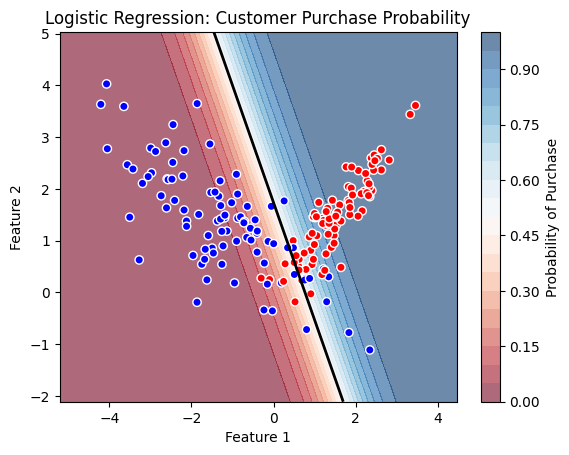



_______________________________________________________________


In [154]:
print("_______________________________________________________________")
print("\n")

X, y = make_classification(n_samples=180, n_features=2, n_redundant=0,
                           n_informative=2, n_clusters_per_class=1,
                           class_sep=1.4, random_state=35)

model = LogisticRegression()
model.fit(X, y)

xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min()-1, X[:, 0].max()+1, 150),
    np.linspace(X[:, 1].min()-1, X[:, 1].max()+1, 150)
)

grid = np.c_[xx.ravel(), yy.ravel()]
zz = model.predict_proba(grid)[:, 1].reshape(xx.shape)

plt.contourf(xx, yy, zz, levels=20, cmap="RdBu", alpha=0.6)
plt.colorbar(label="Probability of Purchase")

plt.contour(xx, yy, zz, levels=[0.5], colors="black", linewidths=2)

plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor="white", cmap="bwr")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Logistic Regression: Customer Purchase Probability")
plt.show()

print("\n")
print("_______________________________________________________________")



Similar to before, a dataset is generated where there are 180 samples with a case of a customer not purchasing a product and a customer purchasing a product.  

Linear regression fits a model to binary classification data, estimates probabilities, and creates a linear decision boundary separatinf the predicted classes.

A graph is made where the scatterpoiints show original observations and the backgropund colors(red & blue) show the probabilities estimated by logistic regression.

The black line is where the predicted probability equals 0.5.
